# Adult income

## Setup (Student 4)
Shared by everyone: same data and same seed.

In [5]:
# Student 4
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn import tree
SEED = 42
TARGET = 'income'

df = pd.read_csv('Preprocessed_dataset.csv')

y = df[TARGET]
X_raw = df.drop(columns=[TARGET])

X = pd.get_dummies(X_raw)
X_cl = X_raw.select_dtypes(include='number')

fn = X.columns.tolist()
cn = df[TARGET].unique()
print(X.shape, X_cl.shape)
df.head()

(45985, 111) (45985, 6)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group,hours_category
0,0.109589,Private,0.599816,11th,0.400000,Never-married,Machine-op-inspct,Own-child,Black,Male,0.000000,0.0,0.397959,United-States,<=50K,Young,Full-time
1,0.287671,Private,0.402918,HS-grad,0.533333,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.000000,0.0,0.500000,United-States,<=50K,Adult,Overtime
2,0.150685,Local-gov,0.683958,Assoc-acdm,0.733333,Married-civ-spouse,Protective-serv,Husband,White,Male,0.000000,0.0,0.397959,United-States,>50K,Adult,Full-time
3,0.369863,Private,0.526083,Some-college,0.600000,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,0.777174,0.0,0.397959,United-States,>50K,Adult,Full-time
4,0.232877,Private,0.571691,10th,0.333333,Never-married,Other-service,Not-in-family,White,Male,0.000000,0.0,0.295918,United-States,<=50K,Adult,Part-time


# [1] Problem (Student 4)
What do you want to solve? Why is it important?

**The problem:** Predicting whether a person earns a high income is a common question in social and economic studies. In this project we want to predict whether an adult's annual income is **less than or equal to \$50,000** or **more than \$50,000**, using demographic, educational, and employment characteristics such as age, education level, occupation, marital status, and hours worked per week.

**Why it is important:** Income is influenced by many factors, not just one. Studying how education, occupation, age, and working hours relate to income helps us understand which factors are linked to higher income levels. These patterns can also be used to build a model that predicts a person's income level automatically, which can support analysis in areas such as economic research and social studies.

# [2] Data Mining Task (Student 4)
Formalize the problem as classification and clustering tasks.

**Classification task:** This is a supervised learning task. Using the attributes of each person (such as age, education, occupation, marital status, and hours worked per week), we build a Decision Tree model that predicts the class label **income**, which has two classes: `<=50K` and `>50K`. The model learns from examples where the income is already known, then is tested on examples it has not seen before.

**Clustering task:** This is an unsupervised learning task. We use the K-means algorithm to group people with similar characteristics into clusters, **without using the income label**. The goal is to discover natural groups in the data and see which characteristics each group shares.

# [3] Data (Student 4)
Describe the dataset (from Phases 1 and 2): source/link, number of rows and columns, attribute types, class label and counts.

In [6]:
# Student 4
print(df.shape)
print(df.dtypes)
print(y.value_counts())
df.sample(5, random_state=SEED)

(45985, 17)
age                float64
workclass           object
fnlwgt             float64
education           object
educational-num    float64
marital-status      object
occupation          object
relationship        object
race                object
gender              object
capital-gain       float64
capital-loss       float64
hours-per-week     float64
native-country      object
income              object
age_group           object
hours_category      object
dtype: object
income
<=50K    34569
>50K     11416
Name: count, dtype: int64


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group,hours_category
39304,0.123288,Private,0.552648,Assoc-acdm,0.733333,Married-civ-spouse,Adm-clerical,Own-child,White,Female,0.0,0.0,0.397959,United-States,<=50K,Adult,Full-time
18306,0.273973,Private,0.676634,HS-grad,0.533333,Never-married,Exec-managerial,Own-child,White,Male,0.0,0.0,0.602041,United-States,<=50K,Adult,Overtime
6916,0.410959,Private,0.580520,HS-grad,0.533333,Separated,Machine-op-inspct,Not-in-family,White,Male,0.0,0.0,0.438776,United-States,<=50K,Middle-aged,Overtime
42746,0.424658,Self-emp-inc,0.760049,10th,0.333333,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,0.397959,United-States,<=50K,Middle-aged,Full-time
38147,0.301370,State-gov,0.393383,HS-grad,0.533333,Divorced,Adm-clerical,Unmarried,White,Female,0.0,0.0,0.397959,United-States,<=50K,Adult,Full-time


**Source:** Adult Income dataset (census data), obtained from Kaggle. Link: https://www.kaggle.com/datasets/wenruliu/adult-income-dataset

**Size:** The preprocessed dataset contains **45,985 records** and **17 columns** (16 attributes and 1 class label).

**Attributes:**
- **Numeric (6):** `age`, `fnlwgt`, `educational-num`, `capital-gain`, `capital-loss`, `hours-per-week` (scaled between 0 and 1 in Phase 2).
- **Categorical (10):** `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `gender`, `native-country`, plus two groups created in Phase 2: `age_group` and `hours_category`.

**Class label:** `income`, with two classes:
- `<=50K`: 34,569 records (about 75%)
- `>50K`: 11,416 records (about 25%)

The classes are imbalanced, since most people belong to `<=50K`.

# [4] Data Preprocessing (Student 4)
Summarize the preprocessing applied in Phase 2 (what, why, on which attributes) with instructor feedback applied.

The following preprocessing techniques were applied in Phase 2:

**1. Missing values.** Some values in `workclass`, `occupation`, and `native-country` were missing (written as `?`). We removed the rows with a missing `occupation` (2,809 rows) and replaced the missing `native-country` values with the most common value.

**2. Duplicates.** We removed 48 duplicate rows because they do not add new information. The dataset now has 45,985 rows (from 48,842).

**3. Log transformation.** We applied a log transformation to `fnlwgt`, `capital-gain`, and `capital-loss` because most of their values are small and a few are very large. This reduced the skewness, although `capital-loss` changed only a little because most of its values are 0.

**4. Discretization.** We created `age_group` from `age` and `hours_category` from `hours-per-week`, because groups are easier to understand than exact numbers.

**5. Normalization.** We scaled the six numeric attributes to the range 0 to 1 using Min-Max scaling, so no attribute is bigger just because of its scale.

The raw data was kept in `Raw_dataset.csv`, and the processed data was saved in `Preprocessed_dataset.csv`.



In [7]:
raw = pd.read_csv('Raw_dataset.csv')

print("Raw dataset:", raw.shape)
display(raw.head())

print("Preprocessed dataset:", df.shape)
display(df.head())

Raw dataset: (48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


Preprocessed dataset: (45985, 17)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group,hours_category
0,0.109589,Private,0.599816,11th,0.400000,Never-married,Machine-op-inspct,Own-child,Black,Male,0.000000,0.0,0.397959,United-States,<=50K,Young,Full-time
1,0.287671,Private,0.402918,HS-grad,0.533333,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.000000,0.0,0.500000,United-States,<=50K,Adult,Overtime
2,0.150685,Local-gov,0.683958,Assoc-acdm,0.733333,Married-civ-spouse,Protective-serv,Husband,White,Male,0.000000,0.0,0.397959,United-States,>50K,Adult,Full-time
3,0.369863,Private,0.526083,Some-college,0.600000,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,0.777174,0.0,0.397959,United-States,>50K,Adult,Full-time
4,0.232877,Private,0.571691,10th,0.333333,Never-married,Other-service,Not-in-family,White,Male,0.000000,0.0,0.295918,United-States,<=50K,Adult,Part-time


# [5] Data Mining Technique

## 5.1 Classification: Decision Tree
We use the `DecisionTreeClassifier` from `sklearn.tree` to predict the class label `income` (<=50K / >50K), because decision trees handle both numeric and categorical attributes and produce a tree we can read to see which attributes separate the two classes. We build two models with different attribute selection measures: the Gini index, `DecisionTreeClassifier(criterion="gini")`, which is the default, and information gain, `DecisionTreeClassifier(criterion="entropy")`. Scikit-learn only accepts numerical data, so the categorical attributes are encoded with `pd.get_dummies`. For each measure, the data is split with `train_test_split` into three partitions (90/10, 80/20, 70/30) with `random_state=42`. The models are evaluated with `metrics.accuracy_score`, `confusion_matrix` and `ConfusionMatrixDisplay`, and the tree is visualized with `tree.plot_tree`.

## 5.2 Clustering: K-means (Student 3)
Why K-means, package/methods (`sklearn.cluster.KMeans`), which columns are used (label excluded), and **justification of the three K values**.

We selected K-means because it groups records with similar numerical characteristics without using the target label. We used KMeans from sklearn.cluster.

The clustering uses numerical features from the preprocessed dataset (X_cl). The target column income is excluded because clustering is an unsupervised learning task.

We compare K = 2, K = 3, and K = 4 to investigate which number of clusters provides the best separation. We use the Silhouette Score and the Elbow Method to evaluate the results. These three values allow us to compare different clustering solutions and select the best K based on the evaluation results.

# [6] Evaluation and Comparison

## 6.1 Classification - Gini (Student 1)

Accuracy (90/10): 0.80734942378778
[[3030  456]
 [ 430  683]]


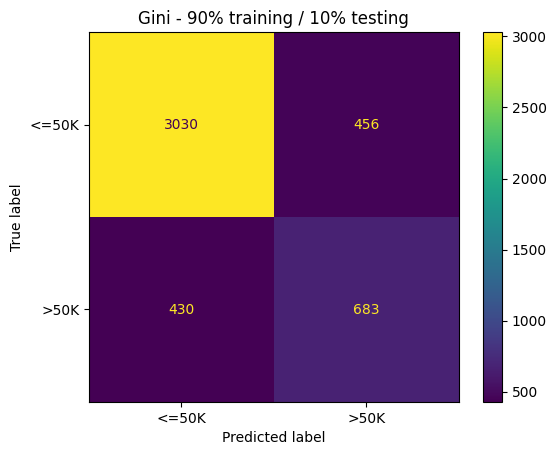

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

clf1 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf1 = clf1.fit(X_train, y_train)
y_pred = clf1.predict(X_test)

acc1 = metrics.accuracy_score(y_test, y_pred)
print("Accuracy (90/10):", acc1)
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(clf1, X_test, y_test, display_labels=cn)
plt.title("Gini - 90% training / 10% testing")
plt.show()

**Interpretation (90/10):** The accuracy is 80.73%. The model correctly classified 3030 of 3486 `<=50K` cases (about 87%) but only 683 of 1113 `>50K` cases (about 61%). It makes more mistakes on the `>50K` class.


Accuracy (80/20): 0.8013482657388279
[[6024  948]
 [ 879 1346]]


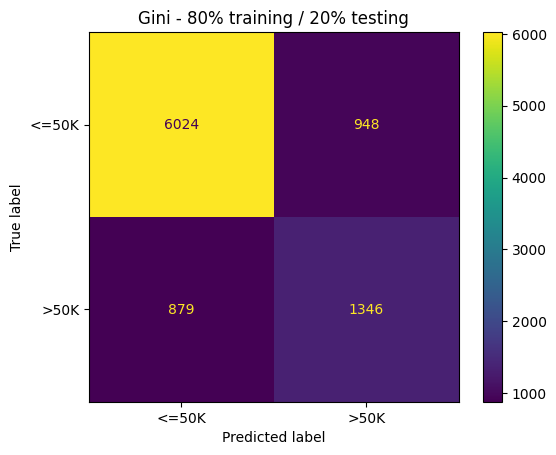

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf2 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf2 = clf2.fit(X_train, y_train)
y_pred = clf2.predict(X_test)

acc2 = metrics.accuracy_score(y_test, y_pred)
print("Accuracy (80/20):", acc2)
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(clf2, X_test, y_test, display_labels=cn)
plt.title("Gini - 80% training / 20% testing")
plt.show()

**Interpretation (80/20):** The accuracy is 80.13%, the lowest of the three partitions. The model correctly classified 6024 of 6972 `<=50K` cases (about 86%) but only 1346 of 2225 `>50K` cases (about 60%).

Accuracy (70/30): 0.8105972745723398
[[9082 1307]
 [1306 2101]]


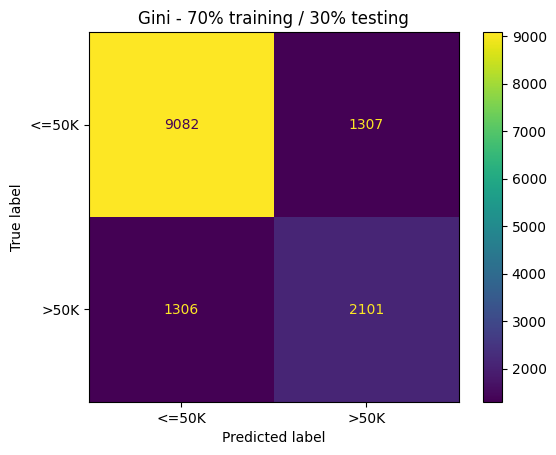

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf3 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf3 = clf3.fit(X_train, y_train)
y_pred = clf3.predict(X_test)

acc3 = metrics.accuracy_score(y_test, y_pred)
print("Accuracy (70/30):", acc3)
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(clf3, X_test, y_test, display_labels=cn)
plt.title("Gini - 70% training / 30% testing")
plt.show()

**Interpretation (70/30):** The accuracy is 81.06%, the highest of the three partitions. The model correctly classified 9082 of 10389 `<=50K` cases (about 87%) and 2101 of 3407 `>50K` cases (about 62%).

In [11]:
gini_table = pd.DataFrame(
    [[round(acc1, 4), round(acc2, 4), round(acc3, 4)]],
    columns=["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"],
    index=["Accuracy"])
gini_table

,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8073,0.8013,0.8106


**Interpretation of the Gini results:** The best Gini accuracy is obtained with the 70/30 partition (81.06%), followed by 90/10 (80.73%) and 80/20 (80.13%). The difference between the partitions is less than 1%, so the partition size has little effect on the Gini tree. In all partitions the model predicts the `<=50K` class (87%) better than the `>50K` class (61%) because the dataset is imbalanced (about 75% of the records are `<=50K`).

## 6.2 Classification - Entropy (Student 2)

### Entropy - 90% training / 10% testing

Accuracy (90/10): 0.8043052837573386
Accuracy (90/10) in %: 80.43
[[3007  479]
 [ 421  692]]


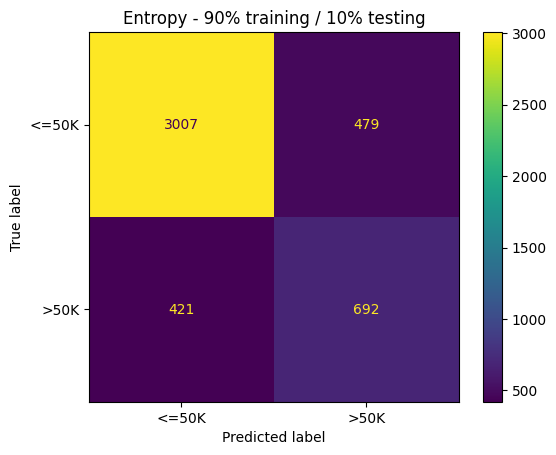

In [12]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X, y, test_size=0.1, random_state=42)

entropy_clf1 = DecisionTreeClassifier(criterion="entropy", random_state=42)
entropy_clf1 = entropy_clf1.fit(X_train_e, y_train_e)
entropy_pred1 = entropy_clf1.predict(X_test_e)

entropy_acc1 = metrics.accuracy_score(y_test_e, entropy_pred1)
print("Accuracy (90/10):", entropy_acc1)
print("Accuracy (90/10) in %:", round(entropy_acc1 * 100, 2))

entropy_cm1 = confusion_matrix(y_test_e, entropy_pred1)
print(entropy_cm1)
ConfusionMatrixDisplay.from_estimator(entropy_clf1, X_test_e, y_test_e, display_labels=cn)
plt.title("Entropy - 90% training / 10% testing")
plt.show()

**Interpretation (90/10):** The accuracy is **80.43%**. The test set has 4,599 records: 3,699 were predicted correctly (3,007 + 692) and 900 were wrong. The model correctly classified 3,007 of 3,486 `<=50K` records (about 86%), but only 692 of 1,113 `>50K` records (about 62%). So the `>50K` class has many more errors: 421 high-income people were predicted as `<=50K`.

### Entropy - 80% training / 20% testing

Accuracy (80/20): 0.8083070566489072
Accuracy (80/20) in %: 80.83
[[6068  904]
 [ 859 1366]]


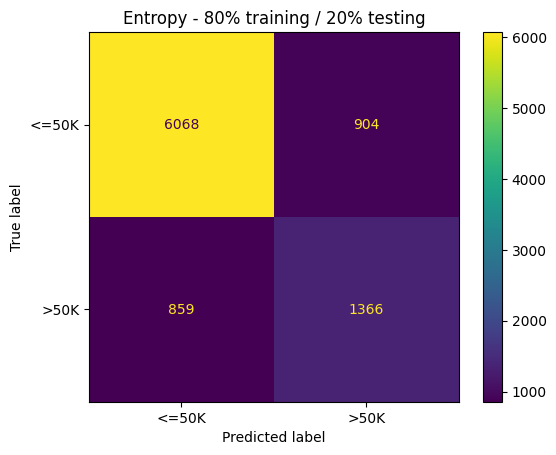

In [13]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X, y, test_size=0.2, random_state=42)

entropy_clf2 = DecisionTreeClassifier(criterion="entropy", random_state=42)
entropy_clf2 = entropy_clf2.fit(X_train_e, y_train_e)
entropy_pred2 = entropy_clf2.predict(X_test_e)

entropy_acc2 = metrics.accuracy_score(y_test_e, entropy_pred2)
print("Accuracy (80/20):", entropy_acc2)
print("Accuracy (80/20) in %:", round(entropy_acc2 * 100, 2))

entropy_cm2 = confusion_matrix(y_test_e, entropy_pred2)
print(entropy_cm2)
ConfusionMatrixDisplay.from_estimator(entropy_clf2, X_test_e, y_test_e, display_labels=cn)
plt.title("Entropy - 80% training / 20% testing")
plt.show()

**Interpretation (80/20):** The accuracy is **80.83%**. Out of 9,197 test records, 7,434 were correct (6,068 + 1,366) and 1,763 were wrong. The model correctly classified 6,068 of 6,972 `<=50K` records (about 87%) and 1,366 of 2,225 `>50K` records (about 61%). Again, the `>50K` class is weaker(859 records predicted as `<=50K`).

### Entropy - 70% training / 30% testing

Accuracy (70/30): 0.8108872136851262
Accuracy (70/30) in %: 81.09
[[9081 1308]
 [1301 2106]]


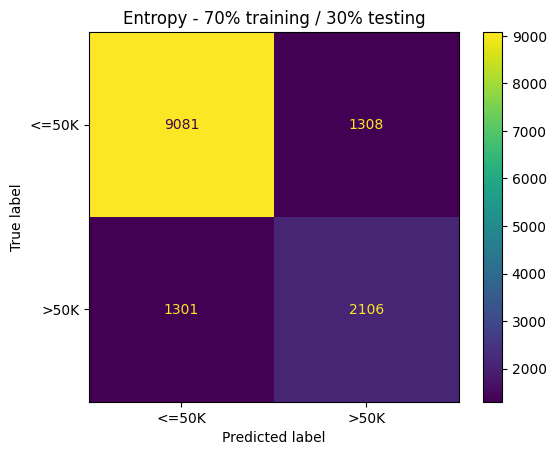

In [14]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X, y, test_size=0.3, random_state=42)

entropy_clf3 = DecisionTreeClassifier(criterion="entropy", random_state=42)
entropy_clf3 = entropy_clf3.fit(X_train_e, y_train_e)
entropy_pred3 = entropy_clf3.predict(X_test_e)

entropy_acc3 = metrics.accuracy_score(y_test_e, entropy_pred3)
print("Accuracy (70/30):", entropy_acc3)
print("Accuracy (70/30) in %:", round(entropy_acc3 * 100, 2))

entropy_cm3 = confusion_matrix(y_test_e, entropy_pred3)
print(entropy_cm3)
ConfusionMatrixDisplay.from_estimator(entropy_clf3, X_test_e, y_test_e, display_labels=cn)
plt.title("Entropy - 70% training / 30% testing")
plt.show()

**Interpretation (70/30):** The accuracy is **81.09%**, the highest of the three Entropy partitions. Out of 13,796 test records, 11,187 were correct (9,081 + 2,106) and 2,609 were wrong. The model correctly classified 9,081 of 10,389 `<=50K` records (about 87%) and 2,106 of 3,407 `>50K` records (about 62%). The pattern is the same as the other partitions: the `>50K` class is harder to predict.

### Entropy accuracy table

In [15]:
entropy_table = pd.DataFrame(
    [[round(entropy_acc1, 4), round(entropy_acc2, 4), round(entropy_acc3, 4)]],
    columns=["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"],
    index=["Accuracy"])
entropy_table

,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8043,0.8083,0.8109


**Interpretation of the Entropy results:** The best Entropy accuracy is with the **70/30** partition (81.09%), then 80/20 (80.83%), and the lowest is **90/10** (80.43%). So more training data did not give a better result here. The difference between the best and the worst partition is only about 0.66 percentage points, which is small.

One likely reason is that the 90/10 test set is the smallest (4,599 records), so its accuracy depends more on which records happen to be in it. Also, the tree is grown without any depth limit, so it learns the training data very closely in every partition, and adding more training records does not change the test accuracy much. In all partitions, about 86-87% of `<=50K` records are classified correctly but only about 61-62% of `>50K` records, because the dataset is imbalanced (about 75% `<=50K`).

## 6.3 Gini vs. Entropy Comparison (Student 2)


In [16]:
compare_table = pd.DataFrame(
    [[round(acc1, 4), round(acc2, 4), round(acc3, 4)],
     [round(entropy_acc1, 4), round(entropy_acc2, 4), round(entropy_acc3, 4)]],
    columns=["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"],
    index=["Gini", "Entropy"])
compare_table

,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Gini,0.8073,0.8013,0.8106
Entropy,0.8043,0.8083,0.8109


The table shows that the two methods give very close accuracy in all partitions (all values are between 80.1% and 81.1%). Gini is better in the 90/10 partition, and Entropy is better in the 80/20 and 70/30 partitions. The details are below.

### Best method for each partition(extra)

In [17]:
partitions = ["90/10", "80/20", "70/30"]
gini_list = [acc1, acc2, acc3]
entropy_list = [entropy_acc1, entropy_acc2, entropy_acc3]

for i in range(3):
    if entropy_list[i] > gini_list[i]:
        winner = "Entropy"
    elif gini_list[i] > entropy_list[i]:
        winner = "Gini"
    else:
        winner = "Tie"
    difference = abs(entropy_list[i] - gini_list[i]) * 100
    print(partitions[i], "-> Gini:", round(gini_list[i] * 100, 2), "% | Entropy:", round(entropy_list[i] * 100, 2),
          "% | Better:", winner, "| Difference:", round(difference, 2), "percentage points")

90/10 -> Gini: 80.73 % | Entropy: 80.43 % | Better: Gini | Difference: 0.3 percentage points
80/20 -> Gini: 80.13 % | Entropy: 80.83 % | Better: Entropy | Difference: 0.7 percentage points
70/30 -> Gini: 81.06 % | Entropy: 81.09 % | Better: Entropy | Difference: 0.03 percentage points


### Best method overall(extra)

In [18]:
all_results = pd.Series({"Gini 90/10": acc1, "Gini 80/20": acc2, "Gini 70/30": acc3,
                         "Entropy 90/10": entropy_acc1, "Entropy 80/20": entropy_acc2, "Entropy 70/30": entropy_acc3})
print(all_results.sort_values(ascending=False))

print("\nAverage accuracy over the three partitions:")
print(compare_table.mean(axis=1))

Entropy 70/30    0.810887
Gini 70/30       0.810597
Entropy 80/20    0.808307
Gini 90/10       0.807349
Entropy 90/10    0.804305
Gini 80/20       0.801348
dtype: float64

Average accuracy over the three partitions:
Gini       0.806400
Entropy    0.807833
dtype: float64


Among the six tested configurations, the highest test accuracy is **Entropy with the 70/30 partition (81.09%)**. Gini with 70/30 is second (81.06%), only 4 correct records behind. Entropy is better in 2 of the 3 partitions, and its average accuracy over the three partitions is slightly higher than Gini's.

So **Entropy is the best-performing method among the configurations we tested**, but the differences are very small (less than 1 percentage point) so we cannot say that Entropy is clearly better than Gini in general. With a different random split, the order could change.

Also, accuracy alone does not show all the errors. Because about 75% of the records are `<=50K`, a model can get a high accuracy while still missing many `>50K` records. The confusion matrices show that both methods correctly find only about 61-62% of the `>50K` records.

### Comparison chart

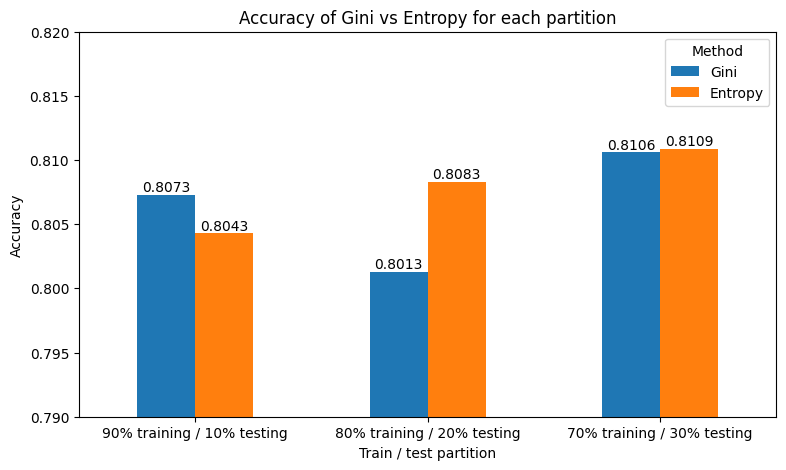

In [19]:
ax = compare_table.T.plot(kind="bar", figsize=(9, 5))
plt.title("Accuracy of Gini vs Entropy for each partition")
plt.xlabel("Train / test partition")
plt.ylabel("Accuracy")
plt.ylim(0.79, 0.82)
plt.xticks(rotation=0)
plt.legend(title="Method")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f")
plt.show()

The chart shows that Gini is higher only in 90/10, while Entropy is higher in 80/20 and 70/30. Both methods reach their best accuracy with the 70/30 partition. Note that the y-axis starts at 0.79, not 0, to make the small differences visible. This makes the gaps look bigger than they really are, since all bars are between 0.80 and 0.82.

## 6.4 Clustering - K-means (Student 3)

In [20]:
K_VALUES = [2, 3, 4]
labels_by_k = {}

for k in K_VALUES:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    ).fit(X_cl)

    labels_by_k[k] = km.labels_

    print("K =", k,"| Silhouette Score =",round(silhouette_score(X_cl, km.labels_), 4))


K = 2 | Silhouette Score = 0.5068
K = 3 | Silhouette Score = 0.5541
K = 4 | Silhouette Score = 0.2822


K values: [2, 3, 4]
Inertias: [6009.098116496438, 4328.672747026393, 3428.802851140225]


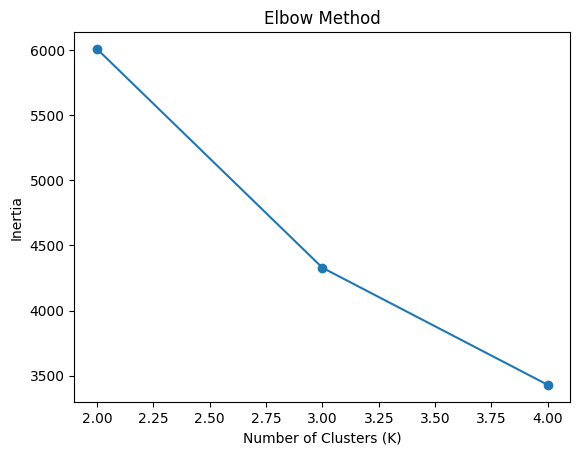

In [21]:
import matplotlib.pyplot as plt

inertias = []

for k in K_VALUES:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )
    km.fit(X_cl)
    inertias.append(km.inertia_)

print("K values:", K_VALUES)
print("Inertias:", inertias)

plt.plot(K_VALUES, inertias, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()


In [22]:
BEST_K = 3

km = KMeans(n_clusters=BEST_K,n_init=10,random_state=SEED)

labels = km.fit_predict(X_cl)

print(pd.Series(labels).value_counts().sort_index())


0    39947
1     2181
2     3857
Name: count, dtype: int64


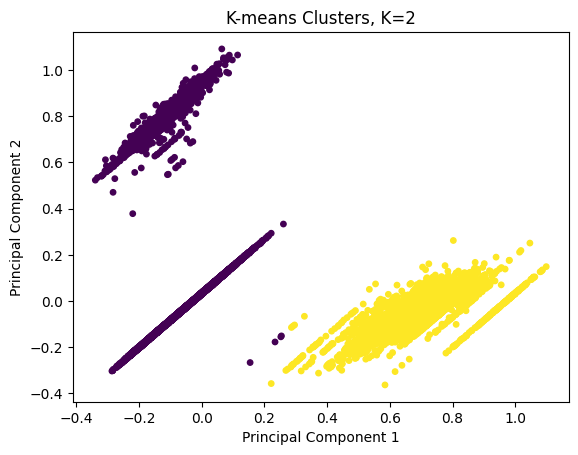

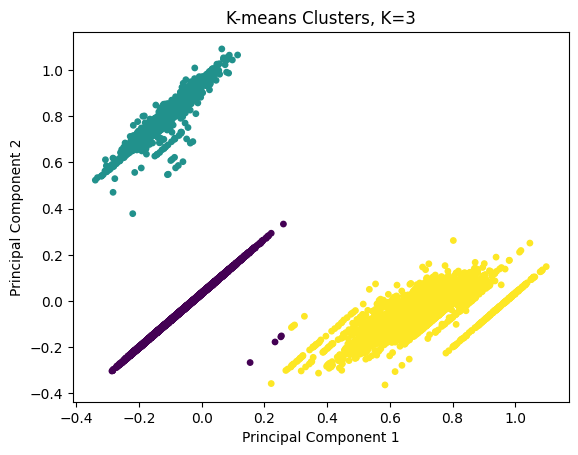

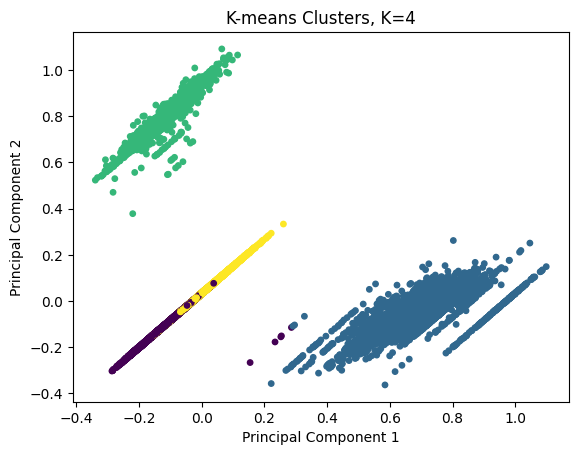

In [23]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pts = PCA(n_components=2, random_state=SEED).fit_transform(X_cl)

for k in K_VALUES:
    plt.figure()
    plt.scatter(pts[:, 0], pts[:, 1], c=labels_by_k[k], cmap='viridis', s=15)
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(f'K-means Clusters, K={k}')
    plt.show()

### PCA Visualization

PCA was used to reduce the numerical features to two principal components for visualization. The scatter plots show the clustering results for K = 2, K = 3, and K = 4 using different colors. The plots help visualize the clustering structure and compare the separation between clusters.

### Cluster Interpretation

Based on the Silhouette Score, K = 3 was selected as the best number of clusters, with a score of 0.5541.

The dataset was divided into three clusters:

- Cluster 0: 39,947 records.
- Cluster 1: 2,181 records.
- Cluster 2: 3,857 records.

Cluster 0 represents the largest group, while Clusters 1 and 2 contain fewer records. These results show that K-means divided the dataset into three groups of different sizes.

# [7] Findings and Discussion

## 7.1 Gini Decision Tree (Student 1)

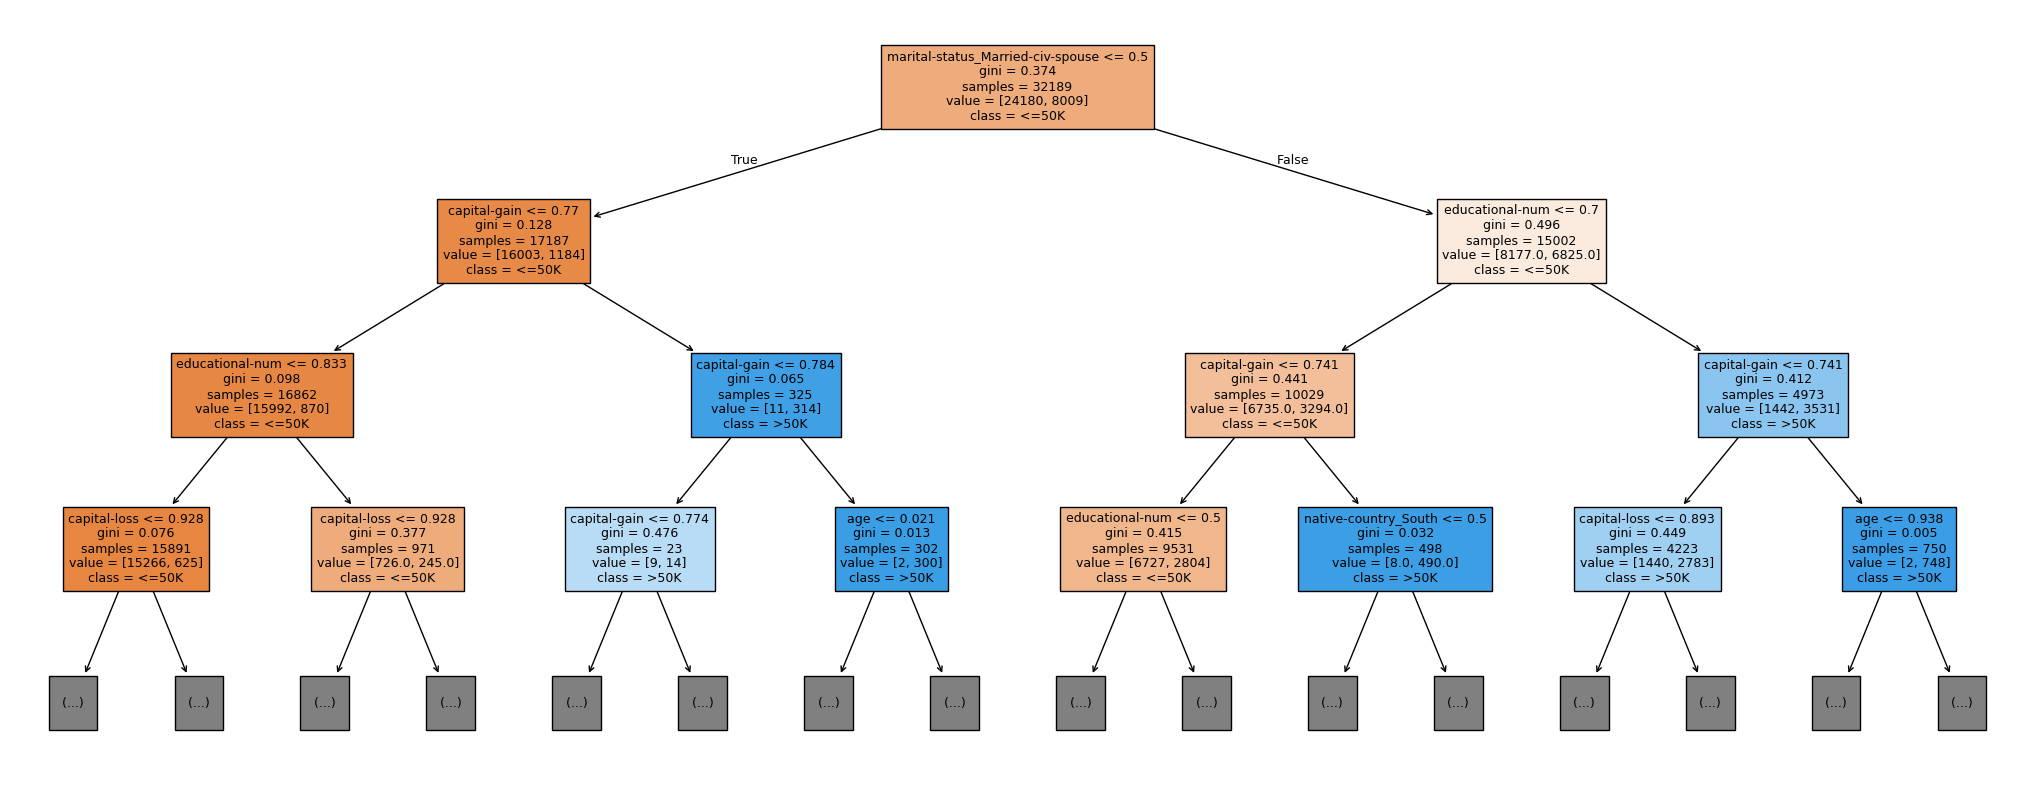

In [24]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf3,
               feature_names=fn,
               class_names=cn,
               filled=True,
               max_depth=3,
               fontsize=9);

fig.savefig("Gini_DT.png")

**Interpretation of the Gini tree (70/30 partition):** The root node splits on `marital-status_Married-civ-spouse`, so marital status is the most informative attribute. Under the non-married branch, the tree splits on `capital-gain` and `educational-num`; under the married branch, it splits on `educational-num` and `capital-gain`. This means that being married, having a higher education level, and having capital gains are the main indicators of income >50K. Only the top 3 levels are plotted because the full tree is too large to read.

**Limitations:** The full tree is very deep (more than 50 levels in some branches), which suggests it may overfit the training data. Also, about 75% of the records belong to `<=50K`, so accuracy alone can be misleading.

## 7.2 Entropy Decision Tree (Student 2)

In [25]:
print("Depth of the full Entropy tree:", entropy_clf3.get_depth())
print("Number of leaves:", entropy_clf3.get_n_leaves())

Depth of the full Entropy tree: 62
Number of leaves: 4651


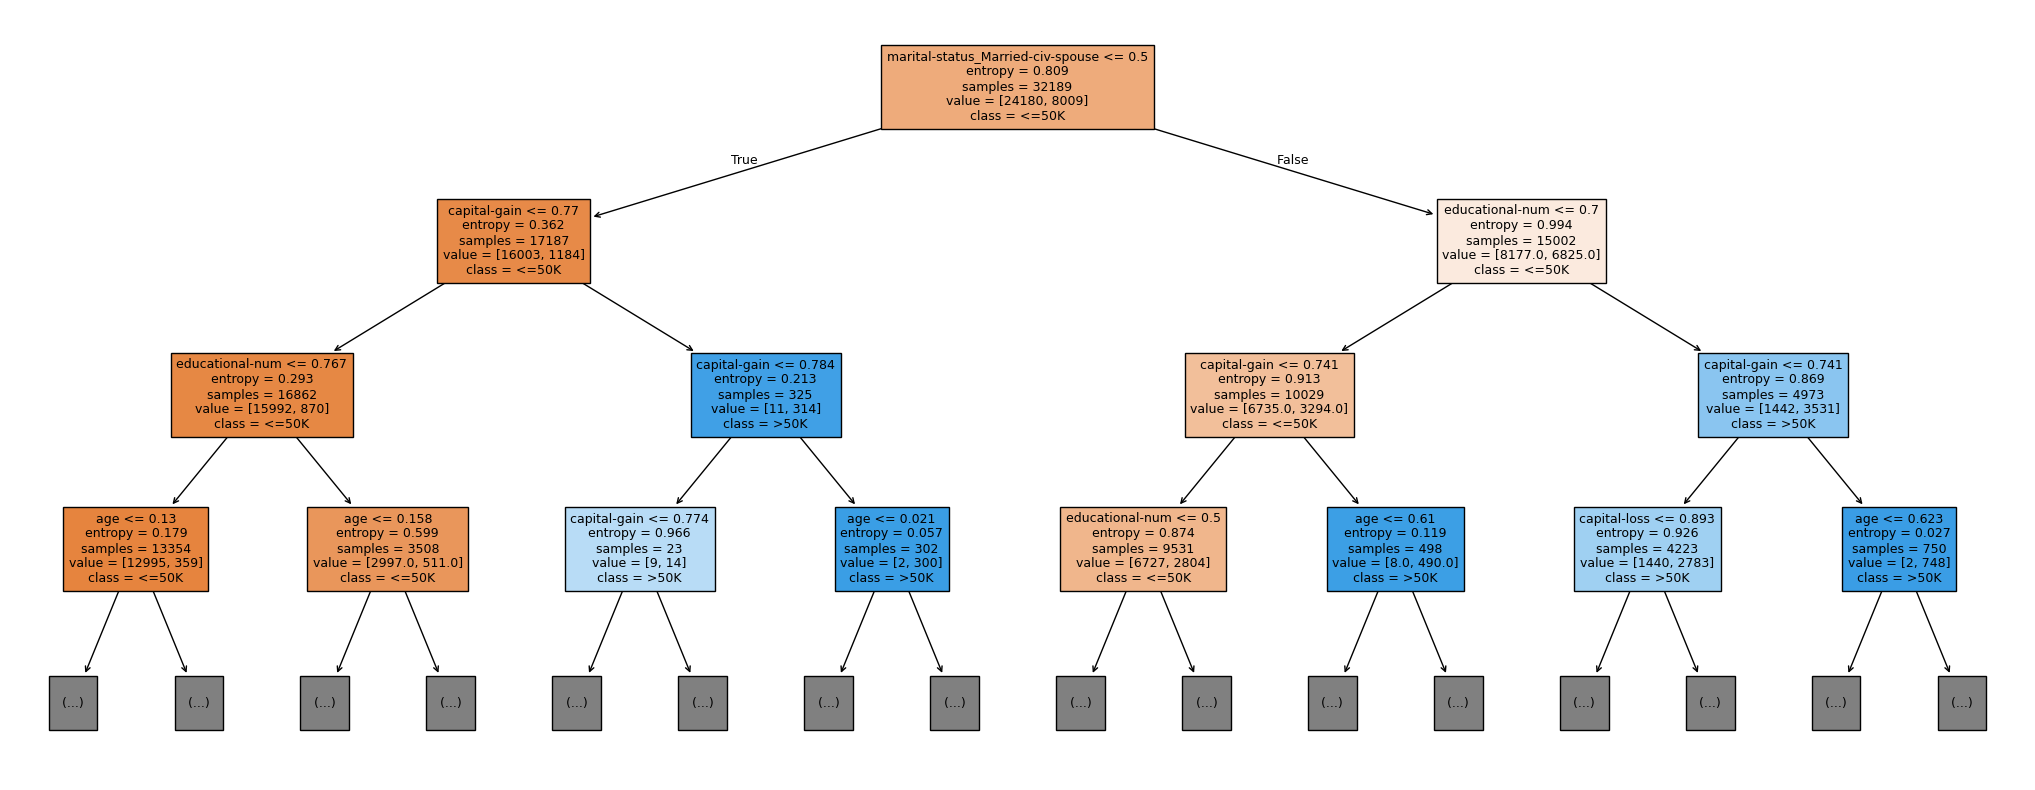

In [26]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(entropy_clf3,
               feature_names=fn,
               class_names=cn,
               filled=True,
               max_depth=3,
               fontsize=9);

fig.savefig("Entropy_DT.png")

### Tree interpretation

Each box shows the split rule, the entropy of the node, the number of training records (`samples`), the number of records in each class (`value`, in the order `<=50K`, `>50K`), and the majority class. The left arrow (True) means the rule is true and the right arrow (False) means it is false. Orange boxes are mostly `<=50K` and blue boxes are mostly `>50K`; a darker color means the node is purer. Note that the numeric attributes were normalized to 0-1 in Phase 2, so the split values are on that scale.

1. **Root node:** The first split is on `marital-status_Married-civ-spouse`. This is a column created by `get_dummies` from the original attribute `marital-status`. It is 1 if the person is married with a civilian spouse, and 0 otherwise. The root has 32,189 training records (about 75% `<=50K`) with entropy 0.809, and this split gives the biggest information gain.

2. **Not married branch (left):** Here about 93% of the records are `<=50K`, so this group is already quite pure. The tree then splits on `capital-gain`: the small group with a high capital gain (about $7,000 or more in the original data, 325 records) is about 97% `>50K`. For the rest, the tree splits on `educational-num` (above about 12.5 on the original 1-16 scale, which means Bachelors or higher), and then on `age`.

3. **Married branch (right):** This group is almost 50/50 (about 55% `<=50K` and 45% `>50K`), with entropy 0.994, close to the maximum. So the tree needs more splits here. It splits on `educational-num` (above about 11.5, which means Assoc-acdm or higher): people with higher education are about 71% `>50K`, while the others are about 33% `>50K`. Both groups are then split on `capital-gain` (about $5,000 or more), and the next level uses `educational-num`, `age` and `capital-loss`.

4. **Upper branches:** The attributes used in the top levels are marital status, capital gain, education level (`educational-num`), age and capital loss.

5. **How the tree classifies income:** Following the branches, a person who is married, has a higher education level, and has a high capital gain reaches a node with 750 records where 748 are `>50K` (almost 100%). A person who is not married, has no large capital gain, and has a lower education level reaches a node with 16,862 records where about 95% are `<=50K`.


### Entropy findings and limitations

- **Best Entropy accuracy:** 81.09% with the 70/30 partition. This is also the highest accuracy among all six tested configurations, but Gini with 70/30 is only 0.03 percentage points lower (4 records).
- **Confusion matrices:** In all three partitions, the model correctly classifies about 86-87% of `<=50K` records but only about 61-62% of `>50K` records. Most errors are high-income people predicted as `<=50K`.
- **Important attributes:** Marital status (the root split), capital gain, education level and age are the main attributes used to separate the classes.
- **What the tree shows:** Being married, having a higher education level and having capital gains lead to the `>50K` class, while not being married with no large capital gain mostly leads to `<=50K`.

**Limitations:**

- The tree has no depth limit, so it grows very deep (depth 62 with 4,651 leaves). It probably overfits the training data, which is also why `fnlwgt` gets a high importance.
- The dataset is imbalanced (about 75% `<=50K`), so accuracy alone hides the weaker performance on the `>50K` class.
- Each partition is one random split with `random_state=42`. The differences between Gini and Entropy are less than 1 percentage point, so a different split could change which method wins.

## 7.3 Cluster Interpretation (Student 3)

In [27]:
cluster_data = X_cl.copy()
cluster_data['Cluster'] = labels

print(cluster_data.groupby('Cluster').mean().round(2))

          age  fnlwgt  educational-num  capital-gain  capital-loss  \
Cluster                                                              
0        0.29    0.53             0.60          0.00           0.0   
1        0.34    0.53             0.67          0.00           0.9   
2        0.37    0.52             0.67          0.77           0.0   

         hours-per-week  
Cluster                  
0                  0.40  
1                  0.44  
2                  0.44  


In [28]:
cluster_data.groupby('Cluster')[['capital-gain', 'capital-loss']].agg(['mean', 'median', 'min', 'max']).round(2)

capital-gain                    capital-loss                 
                mean median   min   max         mean median  min  max
Cluster                                                              
0               0.00   0.00  0.00  0.41          0.0    0.0  0.0  0.0
1               0.00   0.00  0.00  0.00          0.9    0.9  0.6  1.0
2               0.77   0.77  0.41  1.00          0.0    0.0  0.0  0.0

###Cluster Interpretation
The K-means algorithm produced three clusters of different sizes. Cluster 0 contains 39,947 records, Cluster 1 contains 2,181 records, and Cluster 2 contains 3,857 records.

Cluster 0 has the lowest average age and working hours, with low capital-gain and capital-loss values. Cluster 1 is characterized by a high capital-loss value (0.90). In contrast, Cluster 2 has a high capital-gain value (0.77) and the highest average age (0.37). These differences show that the three clusters have different numerical characteristics.

###K-means Conclusion
K-means clustering was applied to six numerical features from the preprocessed dataset, excluding the target column (income). We tested K = 2, K = 3, and K = 4 using the Silhouette Score and the Elbow Method.

K = 3 achieved the highest Silhouette Score of 0.5541, indicating better cluster separation among the tested options. The resulting clusters contained 39,947, 2,181, and 3,857 records. PCA was used to visualize the clustering results in two dimensions. Overall, K = 3 was selected as the best number of clusters based on the evaluation results.

## 7.4 Overall Findings (Student 4)
### Classification findings

**Best model:** The Decision Tree with the **Entropy** criterion and the **70/30** partition gave the highest accuracy among the six tested configurations (**81.09%**). The Gini tree with the same partition is almost identical (**81.06%**, only 4 records behind). In all partitions the two criteria stayed between 80.1% and 81.1%, so the choice of criterion and partition size has a very small effect on this dataset.

**Class-level performance:** With the best model, 9,081 of 10,389 `<=50K` records (about 87%) were classified correctly, but only 2,106 of 3,407 `>50K` records (about 62%). The model is therefore better at recognizing the majority class, which is expected because the classes are imbalanced (about 75% `<=50K` and 25% `>50K`). Overall accuracy alone can hide this weakness.

**Information discovered:** In both trees the root node splits on `marital-status_Married-civ-spouse`, so being married is the most informative attribute for separating the two income classes. For non-married people the next split is on `capital-gain`, and for married people it is on `educational-num` (education level). Age, `capital-gain`, and hours worked per week also appear among the most important attributes. These findings are meaningful and match what we would expect: income is linked to marital status, education, and capital gains.

**Limitation:** The trees were trained without limiting their depth (depth above 50 and thousands of leaves), so they may memorize the training data (overfitting). The tree figures show only the first three levels to stay readable.


### Comparison with the research paper

We compared our results with the paper by Chakrabarty and Biswas [1], which also predicts the income class (`<=50K` / `>50K`) on the Adult dataset using classification. The paper does not use clustering, so we compare the classification results only.

The paper reports an accuracy of 88.16% using a Gradient Boosting Classifier, while our best Decision Tree reaches 81.09%. Our result is lower, which is reasonable because Gradient Boosting combines many trees and was tuned by the authors, while we use a single decision tree without tuning. Even with this difference, both studies show that the income class can be predicted reasonably well from the census attributes.


### Clustering findings

We tested K = 2, 3, and 4. K = 3 had the highest Silhouette Score (0.5541), so it is the best number of clusters. It gave one large cluster (39,947 records) and two small clusters (2,181 and 3,857 records), which differ mainly in capital-loss and capital-gain. The cluster sizes are very unbalanced, and we used only the six numeric attributes.


# [8] References (Student 4)

[1] N. Chakrabarty and S. Biswas, "A statistical approach to adult census income level prediction," in *Proc. Int. Conf. Advances in Computing, Communication Control and Networking (ICACCCN)*, Greater Noida, India, 2018, pp. 207–212.

[2] "Adult Income Dataset," Kaggle. [Online]. Available: https://www.kaggle.com/datasets/wenruliu/adult-income-dataset

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

